# 10 · How precise is WCC photometry on bright stars, and could it catch an Earth transiting an M dwarf?

An Earth-sized planet blocks ~2000 ppm of a 0.2 R☉ mid-M dwarf, ~340 ppm of a 0.5 R☉ early M dwarf and only ~84 ppm of the Sun. A 3-m-class space telescope collects plenty of photons, but the WCC's small (16 ke⁻) pixels saturate quickly on bright stars. The fix is the same as for ground-based precision photometry: defocus to spread the light, and read out fast. The question is what photon-limited precision per hour that buys, as a function of stellar magnitude.

**Instrument / code:** Lazuli WCC, IMX455 (`zwo:r` in focus, `zwo:r+1` one wave defocused, `zwo:bb2` broad band two waves defocused), `wcc-etc` 0.1.0: `Simulation.from_sensorfilter`, `get_peak_pixel`, `get_snr(time, n_reads=...)`.

## Prompt to try in Jupyter AI

> Using `wcc_etc` (Lazuli WCC ETC), compute the photometric precision in ppm per hour versus stellar magnitude (SDSS i, AB, 6–18 mag) for an M4V star (`get_scene("M4V", mag=..., bandpass="sdss_i", magsys="abmag")`).
> Compare three WCC positions built with `Simulation.from_sensorfilter`: `zwo:r` (in focus), `zwo:r+1` (1 wave defocus) and `zwo:bb2` (broad band, 2 waves defocus); also run a G2V star through `zwo:bb2`.
> For each magnitude, use `sim.get_peak_pixel(1.0, units="e-")` to choose the longest frame time (≤ 60 s) that keeps the peak below 80% of `sim.sensor.saturation_e`; treat frames shorter than the 0.25 s minimum read time as saturated.
> Then get the SNR for 1 h total with `sim.get_snr(3600, n_reads=3600/t_frame)`, and convert to ppm/hr = 1e6/SNR.
> Plot ppm/hr vs magnitude (log y) with horizontal lines for Earth-transit depths around 0.2, 0.5 and 1.0 R☉ stars, and print the faintest magnitude where a single 1-h transit gives ≥ 7σ.
> State the assumptions (no systematic noise floor, no readout dead time, aperture choice).

## Setup

Stars are Pickles templates normalised in SDSS i (AB). The three filter positions differ in bandpass *and* PSF: `from_sensorfilter` picks the in-focus Airy or the Zemax-Huygens defocus PSF for that slot. Saturation is the IMX455 full well.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
# plt.style.use('gks')
import wcc_etc
from wcc_etc import get_scene, Simulation

print('wcc_etc', wcc_etc.__version__)
THUMB = Path('thumbs/10_precision_transit_photometry.png')
T_TOTAL, T_MAX, T_MIN = 3600.0, 60.0, 0.25    # s: 1 h total; longest frame; IMX455 min_frame_time
CONFIGS = [('M4V', 'zwo:r'), ('M4V', 'zwo:r+1'), ('M4V', 'zwo:bb2'), ('G2V', 'zwo:bb2')]
MAGS = np.arange(6, 18.01, 0.25)

R_EARTH_RSUN = 0.009168
DEPTHS = {R: (R_EARTH_RSUN / R) ** 2 * 1e6 for R in (0.2, 0.5, 1.0)}
for R, d in DEPTHS.items():
    print(f'Earth transiting a {R} Rsun star: {d:.0f} ppm')

wcc_etc 0.1.0
Earth transiting a 0.2 Rsun star: 2101 ppm
Earth transiting a 0.5 Rsun star: 336 ppm
Earth transiting a 1.0 Rsun star: 84 ppm


## Frame time from saturation, then precision per hour

The peak pixel is linear in time, so one call at 1 s gives the time to reach 80% of full well. That sets the frame time (capped at 60 s), and `n_reads = 3600 / t_frame` splits the hour so that read noise is paid once per frame. We report the 1-hour SNR as ppm/hr.

In [2]:
def precision_curve(spt, label):
    sim = Simulation.from_sensorfilter(label, get_scene(spt, mag=12, bandpass='sdss_i', magsys='abmag'))
    full = sim.sensor.saturation_e.value
    ppm, tframe = np.full(MAGS.size, np.nan), np.full(MAGS.size, np.nan)
    for k, m in enumerate(MAGS):
        sim.update(source__mag=float(m))
        tf = min(T_MAX, 0.8 * full / sim.get_peak_pixel(1.0, units='e-').value)
        if tf < T_MIN:
            continue                      # saturates even in the fastest frame
        n = int(np.ceil(T_TOTAL / tf))
        r = sim.get_snr(T_TOTAL, n_reads=n, warn=False)
        assert not r['saturated']
        ppm[k], tframe[k] = 1e6 / r['snr'], T_TOTAL / n
    return ppm, tframe, sim

t0 = time.time()
curves = {}
for spt, label in CONFIGS:
    ppm, tf, sim = precision_curve(spt, label)
    curves[(spt, label)] = ppm, tf
    ok = np.isfinite(ppm)
    print(f"{spt} {label:8s} PSF={type(sim.default_psf).__name__:10s} brightest unsaturated i = {MAGS[ok][0]:5.2f}"
          f"  best {np.nanmin(ppm):5.1f} ppm/hr (frame {tf[ok][0]:.2f} s)")
print(f'done in {time.time()-t0:.0f} s')

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


M4V zwo:r    PSF=AiryPSF    brightest unsaturated i = 10.50  best  25.3 ppm/hr (frame 0.28 s)


M4V zwo:r+1  PSF=DefocusPSF brightest unsaturated i =  6.25  best   3.4 ppm/hr (frame 0.29 s)


M4V zwo:bb2  PSF=DefocusPSF brightest unsaturated i =  6.00  best   1.6 ppm/hr (frame 0.26 s)


G2V zwo:bb2  PSF=DefocusPSF brightest unsaturated i =  7.25  best   1.6 ppm/hr (frame 0.26 s)
done in 18 s


Precision at a few reference magnitudes:

In [3]:
print(f"{'config':16s}" + ''.join(f'{f"i={m}":>9s}' for m in (8, 10, 12, 14, 16)))
for key, (ppm, tf) in curves.items():
    row = [ppm[np.argmin(abs(MAGS - m))] for m in (8, 10, 12, 14, 16)]
    print(f"{key[0]+' '+key[1]:16s}" + ''.join(f'{v:9.1f}' if np.isfinite(v) else f"{'sat':>9s}" for v in row))

config                i=8     i=10     i=12     i=14     i=16
M4V zwo:r             sat      sat     50.5    126.9    318.7
M4V zwo:r+1           7.5     18.9     47.6    121.0    316.4
M4V zwo:bb2           4.0     10.1     25.5     64.6    168.9
G2V zwo:bb2           2.3      5.8     14.5     36.5     93.2


## Can it catch an Earth?

For a single transit lasting 1 h, the detection SNR is depth / σ(1 h). Below, the faintest i-magnitude giving ≥ 7σ in one transit, using the best (lowest-noise) M4V configuration at each magnitude for the two M dwarfs (M4V as a proxy for the 0.5 R☉ star too), and G2V in `zwo:bb2` for the Sun-like star.

In [4]:
best_m = np.nanmin(np.vstack([curves[('M4V', l)][0] for l in ('zwo:r', 'zwo:r+1', 'zwo:bb2')]), axis=0)
best = {0.2: best_m, 0.5: best_m, 1.0: curves[('G2V', 'zwo:bb2')][0]}   # M4V as proxy for both M dwarfs
faint_limit = {}
for R, d in DEPTHS.items():
    ok = np.isfinite(best[R]) & (d / best[R] >= 7)
    faint_limit[R] = MAGS[ok].max() if ok.any() else np.nan
    star = 'G2V' if R == 1.0 else 'M4V'
    print(f"Earth around {R} Rsun ({d:5.0f} ppm, {star}): 7σ in one 1-h transit for i ≲ {faint_limit[R]:.2f}")

Earth around 0.2 Rsun ( 2101 ppm, M4V): 7σ in one 1-h transit for i ≲ 17.00
Earth around 0.5 Rsun (  336 ppm, M4V): 7σ in one 1-h transit for i ≲ 13.25
Earth around 1.0 Rsun (   84 ppm, G2V): 7σ in one 1-h transit for i ≲ 11.50


## Hero figure

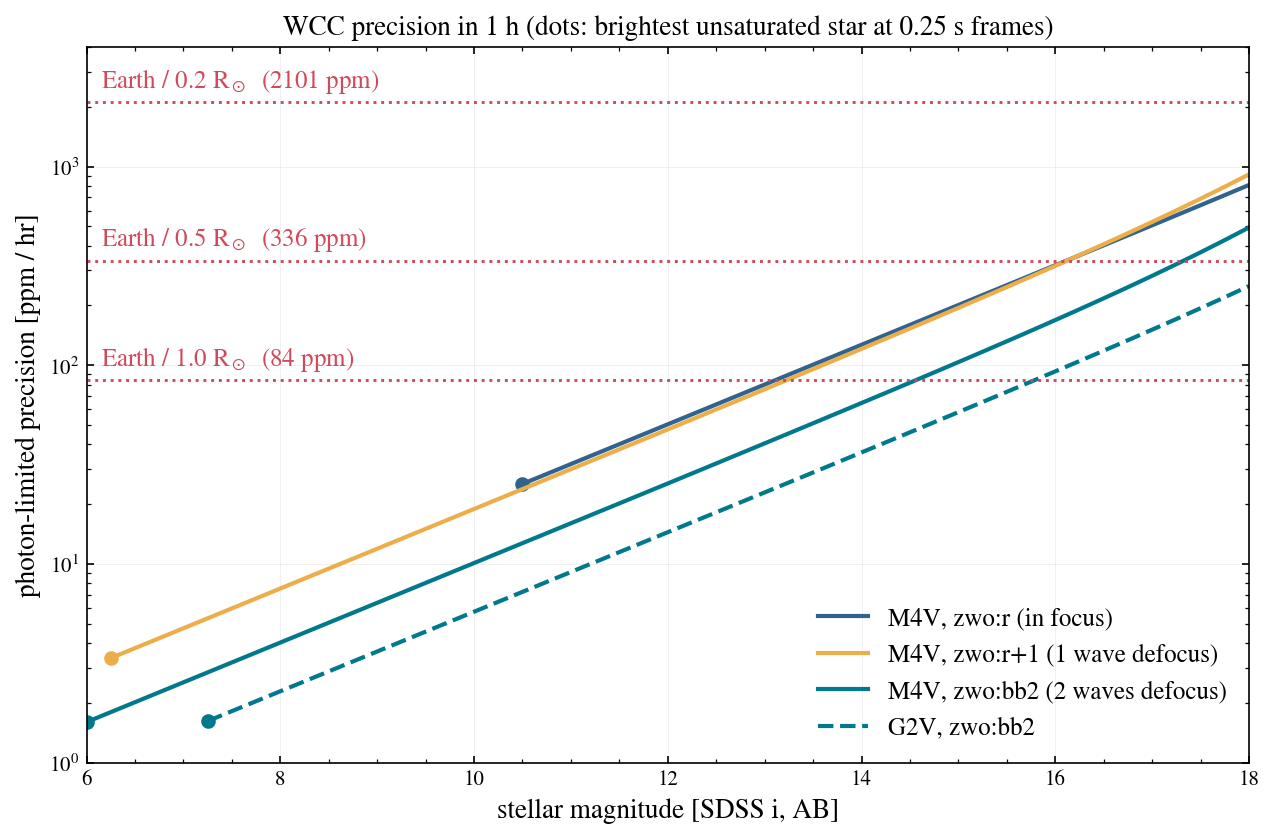

In [5]:
fig, ax = plt.subplots(figsize=(10, 6.2))
style = {('M4V', 'zwo:r'): dict(color='#30638e', label='M4V, zwo:r (in focus)'),
         ('M4V', 'zwo:r+1'): dict(color='#edae49', label='M4V, zwo:r+1 (1 wave defocus)'),
         ('M4V', 'zwo:bb2'): dict(color='#00798c', label='M4V, zwo:bb2 (2 waves defocus)'),
         ('G2V', 'zwo:bb2'): dict(color='#00798c', ls='--', label='G2V, zwo:bb2')}
for key, (ppm, tf) in curves.items():
    ax.semilogy(MAGS, ppm, **style[key])
    ok = np.isfinite(ppm)
    ax.plot(MAGS[ok][0], ppm[ok][0], 'o', color=style[key]['color'], ms=6)   # saturation edge
for R, d in DEPTHS.items():
    ax.axhline(d, color='#d1495b', ls=':', lw=1.4)
    ax.text(6.15, d * 1.08, f'Earth / {R} R$_\\odot$  ({d:.0f} ppm)', ha='left', va='bottom', color='#d1495b', fontsize=12)
ax.set_xlabel('stellar magnitude [SDSS i, AB]')
ax.set_ylabel('photon-limited precision [ppm / hr]')
ax.set_title('WCC precision in 1 h (dots: brightest unsaturated star at 0.25 s frames)')
ax.set_xlim(6, 18); ax.set_ylim(1, 4e3)
ax.legend(loc='lower right', fontsize=12)
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

In the photon-noise limit, yes. The two-wave-defocused broad-band slot (`zwo:bb2`) gives 4.0 / 10.1 / 25.5 / 64.6 ppm per hour on an M4V star at i = 8 / 10 / 12 / 14, and stays unsaturated down to the i = 6 edge of the grid with 0.26 s frames. The in-focus `zwo:r` slot saturates for i < 10.5. A single 1-hour transit of an Earth gives ≥ 7σ around a 0.2 R☉ M dwarf to i ≈ 17.0, around a 0.5 R☉ star to i ≈ 13.25 (using M4V as a proxy), and around a Sun-like G2V to i ≈ 11.5.

## Caveats & next steps

- **These are photon-noise limits only.** The wcc-etc 0.1.0 noise model has photon, dark and read terms. There is **no systematic floor**: flat field, intrapixel response × pointing jitter and gain drift are all missing, and they will set the real precision on bright stars. Stray light, cosmic rays and stellar variability are also missing (M-dwarf flares and spots matter here). The in-focus Airy PSF is diffraction-perfect, so its saturation limit is optimistic.
- **Idealised operations.** The 1-hour SNR assumes no readout dead time between frames. On bright stars the frame time drops to ~0.25 s, about 14,000 full-frame reads per hour, which is a data-volume and readout question rather than a photometry one (subarray reads would help). Transit depths are (R⊕/R★)² with no limb darkening.
- **Ideas to extend:** (1) add an assumed systematic floor in quadrature (e.g. 20–50 ppm/hr) and see where it overtakes photon noise; (2) inject a real transit with wcc-sim + wcc-phot (the repo's `scripts/transit_trappist1b.py` simulates TRAPPIST-1b in defocused frames) to check that the ETC numbers survive centroiding and reference-star noise; (3) use the `lazuli_exo.transit` models bundled with wcc-etc (`TransitModel`, `LightCurveSimulator`) to simulate a full light curve for a known system.